# 07 Summarization (stretch goal): ดวงครึ่งปีของแต่ละราศีใน 3 ประโยค

**เจ้าของ:** Member 1 · **ข้อมูล:** `data/processed/horoscopes.csv`

**คำถาม:**
1. ถ้าสรุปคำทำนาย 6 เดือนของแต่ละราศีเหลือ 3 ประโยค สรุปของแต่ละราศีจะต่างกันไหม
2. วัดด้วย **ROUGE** ระหว่างสรุปของ 12 ราศี ถ้า ROUGE สูงแปลว่าสรุปใช้แทนกันได้ ซึ่งเป็นการวัดความคล้ายอีกแบบนอกจาก cosine ใน 02
3. **"ดวงกลาง" (universal horoscope):** สรุปจากคำทำนาย**ทุกราศี** แล้วนำไปใช้เปิด presentation

**วิธี (L8 Summarization, extractive):**
- **Lead-3** (baseline): เอาประโยคแรกของคำทำนาย 3 อันล่าสุด (ประโยคแรกมักเป็นใจความหลัก)
- **TextRank:** สร้างกราฟที่จุด = ประโยค และเส้น = cosine similarity ของ TF-IDF แล้วจัดอันดับด้วย PageRank ประโยคที่คล้ายประโยคอื่นมากที่สุดคือประโยคที่ "เป็นตัวแทน"
- **LexRank:** เหมือน TextRank แต่เก็บเฉพาะเส้นที่ cosine ≥ 0.1 (threshold) และไม่ถ่วงน้ำหนักเส้น
- เวลาเลือกประโยค จะข้ามประโยคที่คล้ายประโยคที่เลือกไปแล้วเกิน 0.5 เพื่อไม่ให้สรุปซ้ำกันเอง

**ROUGE ภาษาไทย:** แพ็กเกจ `rouge-score` ตัดคำได้แค่ภาษาอังกฤษ จึงคำนวณ ROUGE-1 และ ROUGE-2 เองจากคำที่ตัดด้วย PyThaiNLP

In [1]:
import sys
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.thai_text import THAI_FONT, ZODIAC_TH, clean_text, tokenize

FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
font_manager.fontManager.addfont(THAI_FONT)
THAI_FONT_NAME = font_manager.FontProperties(fname=THAI_FONT).get_name()
plt.rcParams.update({
    "font.family": THAI_FONT_NAME, "font.size": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "normal",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "savefig.dpi": 200, "savefig.bbox": "tight",
})
SITES = ["marumura", "sanook", "thairath", "kapook"]
SIGNS = ["Aries", "Taurus", "Gemini", "Cancer", "Leo", "Virgo", "Libra", "Scorpio",
         "Sagittarius", "Capricorn", "Aquarius", "Pisces"]
SIGN_TH = {en: th for th, en in ZODIAC_TH.items()}
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
pd.set_option("display.max_colwidth", 400)

## 1) แบ่งข้อความเป็น "ประโยค"

ภาษาไทยไม่มีจุดจบประโยค แต่การเว้นวรรคมักคั่นระหว่างวลีหรือประโยค จึงรวมวลีที่อยู่ติดกันจนยาวอย่างน้อย 60 ตัวอักษร (ไม่เกินประมาณ 200) แล้วนับเป็น 1 "ประโยค"
- ใช้ `text_strict` (ตัดย่อหน้าแรกและส่วน "คำแนะนำ" ของ sanook) เพื่อให้สรุปมาจาก**คำทำนาย** ไม่ใช่ย่อหน้าดาวประจำราศีที่ใช้ซ้ำ
- ตัดข้อความที่ลอกซ้ำ (`near_duplicate`) ออก ไม่ให้ประโยคเดียวกันถูกนับหลายครั้ง
- ลบชื่อราศีด้วย `clean_text` เพื่อให้ "ทายราศีจากสรุป" ได้อย่างยุติธรรม

In [2]:
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "horoscopes.csv")
df = df[~df["near_duplicate"]].reset_index(drop=True)

def split_sentences(text, min_chars=60, max_chars=200):
    """Join space-separated Thai phrases into sentence-like pieces of 60-200 characters."""
    pieces, current = [], ""
    for phrase in clean_text(text).split():
        if len(current) >= min_chars and len(current) + len(phrase) > max_chars:
            pieces.append(current)
            current = phrase
        else:
            current = (current + " " + phrase).strip()
    if current:
        if pieces and len(current) < min_chars:
            pieces[-1] += " " + current
        else:
            pieces.append(current)
    return pieces

rows = [(i, j, s) for i, t in enumerate(df["text_strict"]) for j, s in enumerate(split_sentences(t))]
sent = pd.DataFrame(rows, columns=["row", "position", "sentence"]).merge(
    df[["source", "week_monday", "zodiac"]], left_on="row", right_index=True)
sent["tokens"] = sent["sentence"].apply(tokenize)                                   # for TF-IDF (no stopwords)
sent["all_tokens"] = sent["sentence"].apply(lambda s: tokenize(s, remove_stopwords=False))  # for ROUGE
print(f"{len(df)} texts -> {len(sent)} sentences ({len(sent) / len(df):.1f} per text, {sent['sentence'].str.len().mean():.0f} characters)")
sent.groupby("source").size()

1177 texts -> 4577 sentences (3.9 per text, 176 characters)


source
kapook      1566
marumura     850
sanook      1561
thairath     600
dtype: int64

## 2) ฟังก์ชันสรุป: Lead-3, TextRank, LexRank

In [3]:
tfidf = TfidfVectorizer(analyzer=lambda words: words, min_df=2).fit(sent["tokens"])

def pick(order, S, n=3, max_overlap=0.5):
    """Take sentences in ranked order, skipping ones too similar (cosine > max_overlap) to those already taken."""
    chosen = []
    for i in order:
        if all(S[i, j] <= max_overlap for j in chosen):
            chosen.append(i)
        if len(chosen) == n:
            break
    return chosen

def summarize(group, method, n=3):
    """Return the row indices (in `group`) of the n summary sentences."""
    if method == "Lead-3":
        # baseline: the FIRST sentence of the n most recent horoscopes
        # (sites in the same week are put in random order, not alphabetical, so no site is favoured)
        firsts = group[group["position"] == 0].copy()
        firsts["tie_break"] = np.random.default_rng(42).random(len(firsts))
        return list(firsts.sort_values(["week_monday", "tie_break"], ascending=[False, True]).index[:n])
    X = tfidf.transform(group["tokens"])
    S = cosine_similarity(X)
    np.fill_diagonal(S, 0)
    if method == "TextRank":                     # weighted graph, edge weight = cosine
        graph = nx.from_numpy_array(S)
    else:                                        # LexRank: unweighted edges where cosine >= 0.1
        graph = nx.from_numpy_array((S >= 0.1).astype(float))
    scores = nx.pagerank(graph, weight="weight")
    order = sorted(scores, key=scores.get, reverse=True)
    return list(group.index[pick(order, S, n)])

METHODS = ["Lead-3", "TextRank", "LexRank"]
summaries = {m: {z: summarize(sent[sent["zodiac"] == z], m) for z in SIGNS} for m in METHODS}
print("done")

done


## 3) ดวงครึ่งปีของแต่ละราศีใน 3 ประโยค (TextRank)

In [4]:
table = pd.DataFrame({
    "ราศี": [SIGN_TH[z] for z in SIGNS],
    "สรุป 3 ประโยค (TextRank)": [" / ".join(sent.loc[i, "sentence"] for i in summaries["TextRank"][z]) for z in SIGNS],
    "มาจากเว็บ": [", ".join(sent.loc[i, "source"] for i in summaries["TextRank"][z]) for z in SIGNS],
})
table

,ราศี,สรุป 3 ประโยค (TextRank),มาจากเว็บ
0,เมษ,สำหรับคนที่จะไปสัมภาษณ์งาน วันที่ 20 21 อย่าประมาท เผื่อเวลาไว้ให้มากๆ เพราะอาจเจอเหตุ ภัย ที่จะทำให้ไปถึงล่าช้าได้ ความรัก ถ้ากำลังมีอารมณ์รัก ใคร่ เสน่หา คนรัก คู่ครองมากเป็นพิเศษ / การเงิน จากวันที่ 2 เป็นต้นไป ถ้าจะหารายได้เพิ่มเติมก็อยู่ในเกณฑ์ดี แต่ถ้าคิดจะเสี่ยงโชค เก็งกำไร ก็ควรระวัง พิจารณาให้รอบคอบ เพราะอยู่ในระยะที่จะได้มาก เสียหมด ซึ่งวันที่ 5 7 ควรระวังให้มากเป็นพิเศษ / ความรัก ยอ...,"sanook, sanook, sanook"
1,พฤษภ,ถึงจะอยู่ในเกณฑ์ดีที่จะรักษาสัมพันธ์รักให้ราบรื่นไว้ได้ ที่จะไม่ทำให้ทะเลาะวิวาทจนแตกหักกันไปเลย ซึ่งวันที่ 26 28 ควรระวังให้มากเป็นพิเศษ และ จากงาน ภารกิจที่กำลังทำ ก็อาจเป็นโอกาสให้คนโสดได้พบรัก / การเงิน จากงาน ภารกิจที่ทำ ถึงจะอยู่ในเกณฑ์ดีที่จะหารายได้ให้มากขึ้น แต่ถ้าคิดจะเสี่ยงโชค เก็งกำไร ก็ควรพิจารณาให้รอบคอบ เพราะมีเกณฑ์เสี่ยงที่จะทำให้ผิดหวังมากกว่า ซึ่งวันที่ 9 11 / การเงิน หากจะหา...,"sanook, sanook, sanook"
2,เมถุน,การเงิน ถ้าจะหารายได้เพิ่มเติม ก็อยู่ในเกณฑ์ดี แต่ถ้าคิดจะเสี่ยงโชค เก็งกำไร ก็อยู่ในเกณฑ์เสี่ยงที่จะสูญเสียมากกว่า ซึ่งวันที่ 18 และ 22 24 ควรระวังให้มากเป็นพิเศษ การงาน โอกาสมีมากกว่าหนึ่ง ทั้งจากงาน / ครอบครัว วันที่ 13 14 อย่าประมาท เงินทองของมีค่าอาจสูญหาย บริวาร ลูกจ้างในบ้าน อาจก่อเรื่อง ทำให้เดือดร้อน เสียหายได้ สุขภาพ ยังอยู่ในระยะที่ควรระวังการมีเพศสัมพันธ์ที่ฟุ่มเฟือย ที่ไม่ได้ป้องก...,"sanook, sanook, thairath"
3,กรกฎ,เป็นต้น การเงิน ถึงแม้ว่ารายได้ค่อนข้างคงที่แต่ก็ไม่มีปัญหาเรื่องการเงินให้หนักใจ ความรัก คนมีคู่ความสัมพันธ์รักค่อนข้างราบรื่นดี / การเงิน ได้มาก เสียหมด ถ้าคิดจะเสี่ยงโชค เก็งกำไร ซึ่งวันที่ 24 26 ควรระวังให้มากเป็นพิเศษ แต่ถ้าจะหารายได้เพิ่มเติม ก็อยู่ในเกณฑ์ดีที่จะมีโอกาสมากขึ้น แต่ควรระวังการใช้จ่ายฟุ่มเฟือยทั้งของตนเอง และ / พัฒนาสัมพันธ์จนได้ครองคู่อย่างรวดเร็ว แต่ก็อย่าประมาท ตรวจสอบให...,"thairath, sanook, sanook"
4,สิงห์,การเงิน วันที่ 18 20 ถ้าคิดจะเสี่ยงโชค เก็งกำไร ก็อยู่ในเกณฑ์ดีที่จะได้ลาภผล แต่อยู่ในระยะที่ควรระวัง ตั้งสติให้ดีๆ กับการติดต่อ สัมพันธ์ใดๆ เพราะมีเกณฑ์สูงเช่นกันที่จะทำให้ผิดหวัง และ สูญเสียมากกว่า / สัมพันธ์ด้วย เพราะอาจทำให้ เขา เธอ ผู้นั้นไม่พอใจ ไม่อยากร่วมมือด้วย ที่จะทำให้งาน ภารกิจที่คาดหวัง ล้มเหลว ซึ่งวันที่ 10 12 ควรระวังให้มากเป็นพิเศษ ความรัก ก็เช่นกันกับเรื่องงาน วันที่ 10 12 / ...,"sanook, sanook, sanook"
5,กันย์,ที่จะทำให้สูญเสียเงินจำนวนมากได้ ซึ่งวันที่ 19 21 ควรระวังให้มากเป็นพิเศษ การงาน การเจรจา ติดต่อ หรือการสื่อสาร ที่สามารถปรับ เปลี่ยนได้ไปตามสถานการณ์ ก็จะอยู่ในเกณฑ์ดีที่จะทำให้งาน ภารกิจที่กำลังทำ / จึงทำให้ไม่ค่อยมีปัญหาติดขัดในเรื่องการเงิน ความรัก คนมีคู่แม้ว่าจะทะเลาะกันบ้างนิดหน่อยแต่ลึกๆ ในใจก็ยังรักกันดีอยู่ / เจอคนถูกใจ ได้ สุขภาพ ยังอยู่ในระยะที่ควรตั้งสติให้มาก ๆ ที่ควรหลีกเลี่ยงกา...,"sanook, thairath, sanook"
6,ตุลย์,ดูแลตนเองให้มากขึ้น ที่ควรหลีกเลี่ยงการเสพสุรา หรือสารเสพติดใด ๆ เพราะอาจทำให้เจ็บป่วย ไม่สบายมากกว่าที่คิด ครอบครัว ยังอยู่ในระยะที่ควรใส่ใจ ดูแลบุตร ธิดาให้มากขึ้น โดยเฉพาะการใช้สื่อออนไลน์ หรือเรื่องคบหามิตรสหาย เพราะอาจเจอปัญหาร้ายแรง ยาเสพติด / ในช่วงนี้จะมีรายได้เข้ามาตลอดทำให้ไม่มีปัญหาเรื่องการเงินเข้ามาให้หนักใจ ความรัก คนมีคู่ความสัมพันธ์รักยังมั่นคงดีอยู่ แต่อาจจะมีเรื่องให้ทะเลาะกั...,"sanook, thairath, sanook"
7,พิจิก,ศรัทธาเดียวกันกับคนรัก คู่ครอง ถึงจะอยู่ในเกณฑ์ดีที่จะรักษาสัมพันธ์รักให้ราบรื่นไว้ได้ สำหรับคนโสดที่กำลังไขว่คว้าหารัก การใช้สื่อออนไลน์ อาจทำให้พบรัก เจอคนถูกใจ แต่ถ้าเขา เธอ คนนั้น / จนไม่อยากอยู่ใกล้ แต่สำหรับคนที่มีคนรัก คู่ครองอยู่แล้ว ก็ควรระวัง และ หลีกเลี่ยงที่แอบมีรักซ้อน ซ่อนรัก เพราะอาจนำเหตุ ภัยอันตรายมาให้ สุขภาพ อยู่ในเกณฑ์ดี แต่เป็นระยะที่ควรระวัง อย่าประมาท / ก็อาจเป็นโอกาสให้...,"sanook, sanook, sanook"
8,ธนู,ก็อาจเป็นโอกาสให้คนโสดได้พบรัก เจอคนถูกใจที่เขา เธอ ก็พร้อมจะร่วมสานรัก พัฒนาสัมพันธ์จนได้ครองคู่ แต่ถ้าเป็นรักออนไลน์ ก็อย่าประมาท ตั้งสติให้ดีๆ กับคำเรียกร้อง ขอโน่น ขอนี่ จากเขา เธอ คนนั้น / แม้ว่าเงินที่จะเข้ามาในช่วงนี้จะไม่ใช่เงินก้อนใหญ่ แต่ก็เป็นเงินที่เข้ามาเรื่อยๆ ความรัก คนมีคู่ยิ่งนานวันยิ่งรักกันมากขึ้น / การงาน ช่วงนี้ดวงกำลังตามงานกำลังขึ้น ชาว มีโอกาสที่จะประสบความสำเร็จในเรื่อ...,"sanook, thairath, thairath"
9,มังกร,รวมถึงไม่มีแอบแฝงซ่อนเร้นในเรื่องเงินๆ ทองๆ ถึงจ

In [5]:
# Which sites do the chosen summary sentences come from?
picked = pd.DataFrame([{"method": m, "source": sent.loc[i, "source"]}
                       for m in METHODS for z in SIGNS for i in summaries[m][z]])
pd.crosstab(picked["method"], picked["source"]).reindex(index=METHODS, columns=SITES, fill_value=0)

source,marumura,sanook,thairath,kapook
method,,,,
Lead-3,8,9,7,12
TextRank,0,24,11,1
LexRank,2,24,10,0


**จากตารางสรุป พบว่า**
- สรุป 3 ประโยคของแต่ละราศี**อ่านแล้วแทบแยกไม่ออก** ทุกราศีพูดเรื่องเดียวกัน คือ การเงิน "หารายได้เพิ่มเติมอยู่ในเกณฑ์ดี แต่ถ้าเสี่ยงโชค เก็งกำไร ควรระวัง", ความรัก "คนโสดอาจพบรัก", "ควรระวังให้มากเป็นพิเศษ"
- **ไม่มีสรุปของราศีไหนที่บอกได้ว่าเป็นราศีนั้น** ถ้าสลับชื่อราศีในตารางก็ไม่มีใครรู้
- **TextRank เลือกประโยคจาก sanook 24 จาก 36 ประโยค** เพราะ sanook มีประโยคเยอะและใช้วลีมาตรฐานซ้ำ (เช่น "อยู่ในเกณฑ์ดี", "ควรระวังให้มากเป็นพิเศษ") ประโยคเหล่านี้จึงอยู่ "ตรงกลาง" ของกราฟ ส่วน Lead-3 กระจายครบทุกเว็บตามที่ออกแบบไว้

*ข้อจำกัด:* "ประโยค" ได้จากการรวมวลีที่เว้นวรรค (ภาษาไทยไม่มีจุด) บางประโยคจึงขึ้นต้นกลางความ เช่น "ถึงจะอยู่ในเกณฑ์ดี..."

## 4) ROUGE: สรุปของแต่ละราศีใช้แทนกันได้ไหม

**ROUGE-N F1** = ความคล้ายจาก n-gram ที่ตรงกัน (N = 1 คือคำเดี่ยว, N = 2 คือคู่คำที่ติดกัน) ระหว่างสรุป 2 อัน ยิ่งสูงยิ่งเหมือน
ตัวเปรียบเทียบ: สรุป 3 ประโยคของแต่ละ**เว็บ** (TextRank วิธีเดียวกัน) ถ้าสรุปของราศีคล้ายกันมากกว่าสรุปของเว็บ ก็แปลว่าราศีใช้แทนกันได้

In [6]:
def ngrams(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

def rouge_f1(a, b, n):
    """ROUGE-N F1 between two token lists (symmetric)."""
    ga, gb = ngrams(a, n), ngrams(b, n)
    overlap = sum((ga & gb).values())
    if overlap == 0:
        return 0.0
    precision, recall = overlap / sum(gb.values()), overlap / sum(ga.values())
    return 2 * precision * recall / (precision + recall)

def summary_tokens(indices):
    return [w for i in indices for w in sent.loc[i, "all_tokens"]]

def rouge_matrix(groups, sums, n):
    toks = {g: summary_tokens(sums[g]) for g in groups}
    return pd.DataFrame([[rouge_f1(toks[a], toks[b], n) for b in groups] for a in groups], index=groups, columns=groups)

site_summaries = {s: summarize(sent[sent["source"] == s], "TextRank") for s in SITES}
off = lambda m: m.values[np.triu_indices(len(m), 1)]
rows = []
for n in (1, 2):
    for method in METHODS:
        rows.append({"ROUGE": f"ROUGE-{n}", "สรุปด้วย": method, "ราศี vs ราศี": off(rouge_matrix(SIGNS, summaries[method], n)).mean()})
    rows.append({"ROUGE": f"ROUGE-{n}", "สรุปด้วย": "TextRank (สรุปของแต่ละเว็บ)", "เว็บ vs เว็บ": off(rouge_matrix(SITES, site_summaries, n)).mean()})
pd.DataFrame(rows).round(3)

,ROUGE,สรุปด้วย,ราศี vs ราศี,เว็บ vs เว็บ
0,ROUGE-1,Lead-3,0.351,NaN
1,ROUGE-1,TextRank,0.395,NaN
2,ROUGE-1,LexRank,0.386,NaN
3,ROUGE-1,TextRank (สรุปของแต่ละเว็บ),NaN,0.206
4,ROUGE-2,Lead-3,0.091,NaN
5,ROUGE-2,TextRank,0.127,NaN
6,ROUGE-2,LexRank,0.132,NaN
7,ROUGE-2,TextRank (สรุปของแต่ละเว็บ),NaN,0.013


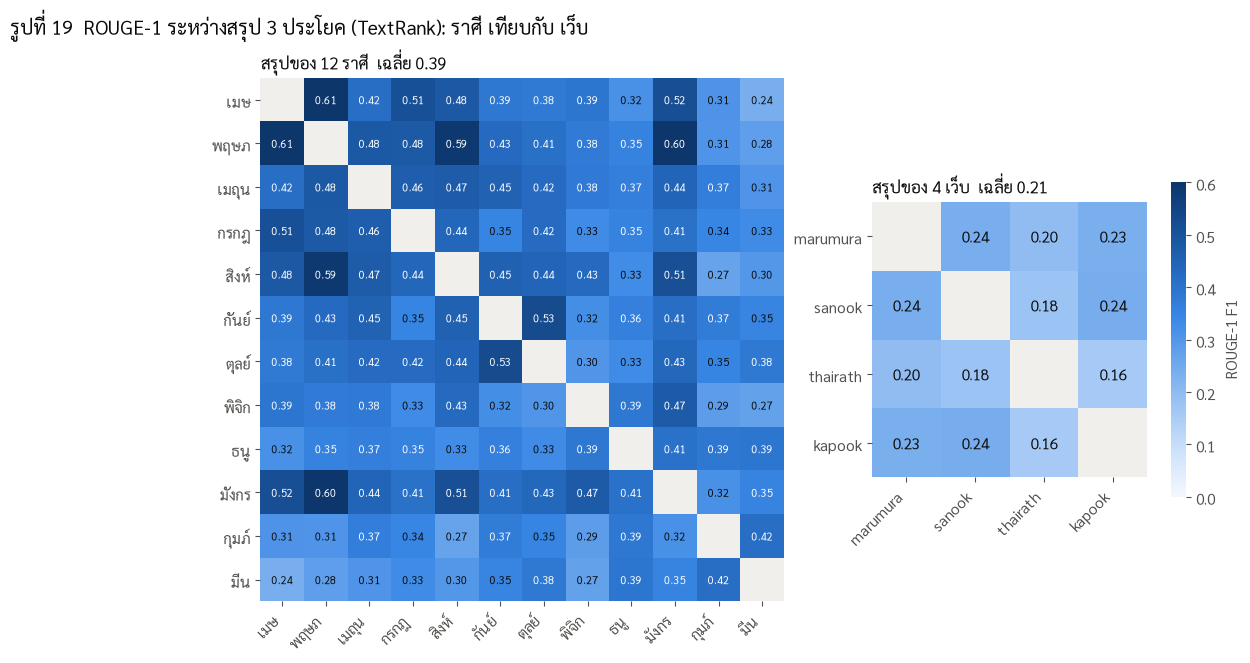

In [7]:
# Figure 19: ROUGE-1 F1 between the 12 sign summaries (left) and between the 4 site summaries (right), TextRank
r_sign = rouge_matrix(SIGNS, summaries["TextRank"], 1)
r_site = rouge_matrix(SITES, site_summaries, 1)
def draw(ax, mat, labels, fontsize, title):
    values = mat.values.copy()
    np.fill_diagonal(values, np.nan)
    cmap = BLUE_RAMP.copy(); cmap.set_bad("#f0efec")
    im = ax.imshow(values, cmap=cmap, vmin=0, vmax=0.6)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if i != j:
                ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center", fontsize=fontsize,
                        color="white" if values[i, j] > 0.35 else "#0b0b0b")
    ax.set_title(title, loc="left")
    return im

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.8), gridspec_kw={"width_ratios": [12, 5.5]})
draw(ax1, r_sign, [SIGN_TH[z] for z in SIGNS], 8, f"สรุปของ 12 ราศี  เฉลี่ย {off(r_sign).mean():.2f}")
im = draw(ax2, r_site, SITES, 11, f"สรุปของ 4 เว็บ  เฉลี่ย {off(r_site).mean():.2f}")
cbar = fig.colorbar(im, ax=[ax1, ax2], shrink=0.6, pad=0.02)
cbar.set_label("ROUGE-1 F1")
cbar.outline.set_visible(False)
fig.suptitle("รูปที่ 19  ROUGE-1 ระหว่างสรุป 3 ประโยค (TextRank): ราศี เทียบกับ เว็บ", x=0.01, ha="left", fontsize=14)
fig.savefig(FIG_DIR / "07_rouge_heatmap.png")
plt.show()

**จากรูปที่ 19 พบว่า**
- สรุปของ **12 ราศี** คล้ายกันเฉลี่ย ROUGE-1 = **0.39** (ROUGE-2 = 0.13)
- สรุปของ **4 เว็บ** คล้ายกันแค่ **0.21** (ROUGE-2 = **0.01** แทบไม่มีคู่คำที่ตรงกันเลย)
- Lead-3 และ LexRank ให้ผลแบบเดียวกัน (ROUGE-1 ระหว่างราศี 0.35 และ 0.39)

คู่ที่คล้ายกันที่สุด เช่น ราศีเมษกับราศีพฤษภ (0.61) และราศีพฤษภกับราศีมังกร (0.60) แชร์วลีเดียวกันเกือบครึ่งหนึ่ง
**แต่ระวัง:** สรุปของราศีมาจาก sanook เป็นส่วนใหญ่ จึงอาจคล้ายกันเพราะคนเขียนคนเดียวกัน ตารางถัดไปตรวจเรื่องนี้

### ตรวจซ้ำแบบควบคุมผู้เขียน

สรุปของ 12 ราศีด้านบนมาจากประโยคของ sanook เป็นส่วนใหญ่ จึงอาจคล้ายกันเพราะ**คนเขียนคนเดียวกัน**
ตรงนี้จึงสรุปแยก **ทีละ (เว็บ, ราศี)** = 48 สรุป แล้วเทียบ ROUGE-1 ใน 2 แบบ:
- **(ก) เว็บเดียวกัน คนละราศี** เช่น สรุปของราศีเมษใน thairath เทียบกับราศีสิงห์ใน thairath
- **(ข) ราศีเดียวกัน คนละเว็บ** เช่น สรุปของราศีเมษใน thairath เทียบกับราศีเมษใน kapook

In [8]:
cell_summary = {(s, z): summarize(sent[(sent["source"] == s) & (sent["zodiac"] == z)], "TextRank")
                for s in SITES for z in SIGNS}
cell_tokens = {key: summary_tokens(idx) for key, idx in cell_summary.items()}
keys = list(cell_tokens)
pairs = []
for a in range(len(keys)):
    for b in range(a + 1, len(keys)):
        (s1, z1), (s2, z2) = keys[a], keys[b]
        if (s1 == s2) != (z1 == z2):                      # exactly one of site / sign is shared
            pairs.append({"แบบ": "(ก) เว็บเดียวกัน คนละราศี" if s1 == s2 else "(ข) ราศีเดียวกัน คนละเว็บ",
                          "ROUGE-1": rouge_f1(cell_tokens[keys[a]], cell_tokens[keys[b]], 1),
                          "ROUGE-2": rouge_f1(cell_tokens[keys[a]], cell_tokens[keys[b]], 2)})
pd.DataFrame(pairs).groupby("แบบ").agg(["mean", "size"]).round(3)

ROUGE-1      ROUGE-2     
                             mean size    mean size
แบบ                                                
(ก) เว็บเดียวกัน คนละราศี   0.426  264   0.147  264
(ข) ราศีเดียวกัน คนละเว็บ   0.224   72   0.011   72

**จากการตรวจซ้ำแบบควบคุมผู้เขียน พบว่า**
- **(ก) เว็บเดียวกัน คนละราศี:** ROUGE-1 = **0.43**, ROUGE-2 = **0.15**
- **(ข) ราศีเดียวกัน คนละเว็บ:** ROUGE-1 = **0.22**, ROUGE-2 = **0.01**

สรุปของ**ราศีต่างกันแต่คนเขียนเดียวกัน** คล้ายกันมากกว่าสรุปของ**ราศีเดียวกันแต่คนเขียนต่างกัน** ประมาณ 2 เท่า (ROUGE-1) และประมาณ **13 เท่า** (ROUGE-2 ซึ่งดูคู่คำที่ติดกัน คือดูสำนวน)
ผลนี้ตรงกับโน้ตบุ๊ก 02 (cosine: เว็บเดียวกันคนละราศีคล้ายกันมากกว่า 3.4 เท่า) แม้ใช้ตัววัดต่างกัน

## 5) เปรียบเทียบวิธีสรุป

ยังไม่มี "สรุปที่ถูกต้อง" ที่คนเขียนไว้ให้เทียบ จึงใช้ตัววัดทางอ้อม 2 ตัว:
- **ความครอบคลุม** = ROUGE-1 recall ของคำในสรุป เทียบกับคำที่พบบ่อย (top 100) ในข้อความทั้งหมดของราศีนั้น
- **ความหลากหลาย** = จำนวนเว็บที่ประโยคในสรุปมาจาก (1–3)

In [9]:
def coverage(indices, zodiac):
    top = [w for w, _ in Counter(w for t in sent.loc[sent["zodiac"] == zodiac, "tokens"] for w in t).most_common(100)]
    summary_words = set(w for i in indices for w in sent.loc[i, "tokens"])
    return np.mean([w in summary_words for w in top])

pd.DataFrame({
    m: {"ความครอบคลุม top-100 คำ (เฉลี่ย 12 ราศี)": np.mean([coverage(summaries[m][z], z) for z in SIGNS]),
        "จำนวนเว็บต่อสรุป (เฉลี่ย)": np.mean([sent.loc[summaries[m][z], "source"].nunique() for z in SIGNS]),
        "ความยาวสรุป (ตัวอักษร)": np.mean([sent.loc[summaries[m][z], "sentence"].str.len().sum() for z in SIGNS])}
    for m in METHODS
}).round(3)

,Lead-3,TextRank,LexRank
ความครอบคลุม top-100 คำ (เฉลี่ย 12 ราศี),0.192,0.293,0.254
จำนวนเว็บต่อสรุป (เฉลี่ย),3.000,1.500,1.500
ความยาวสรุป (ตัวอักษร),561.000,539.250,527.583


**เปรียบเทียบ 3 วิธี:**
- **TextRank** ครอบคลุมคำที่พบบ่อยของราศีมากที่สุด (29% ของ top-100 คำ) เทียบกับ LexRank 25% และ Lead-3 19% เพราะเลือกประโยคที่ "เป็นตัวแทน" ของทั้งกลุ่ม
- **Lead-3** ได้ประโยคจาก 3 เว็บพอดีทุกครั้ง (ตามที่ออกแบบ) แต่เป็นแค่ประโยคแรกของ 3 สัปดาห์ล่าสุด จึงไม่ได้เป็นตัวแทนของทั้ง 6 เดือน
- **LexRank** ให้ผลใกล้ TextRank (ต่างกันแค่เส้นในกราฟไม่ถ่วงน้ำหนัก)

*ข้อจำกัด:* ไม่มีสรุปที่คนเขียนไว้ให้เทียบ (reference summary) จึงวัด ROUGE แบบมาตรฐานไม่ได้ ตัววัด "ความครอบคลุม" เป็นแค่ตัววัดทางอ้อม

## 6) "ดวงกลาง" (universal horoscope): สรุปจากคำทำนายทุกราศี

ใช้ TextRank กับทุกประโยคของทุกราศีและทุกเว็บ (ประมาณ 5,000 ประโยค) แล้วได้ 3 ประโยคที่เป็นตัวแทนของดวง**ทุกราศี**

In [10]:
universal = summarize(sent, "TextRank")
for k, i in enumerate(universal, 1):
    print(f"{k}. {sent.loc[i, 'sentence']}")
    print(f"   (มาจาก {sent.loc[i, 'source']}, ราศี{SIGN_TH[sent.loc[i, 'zodiac']]}, สัปดาห์ {sent.loc[i, 'week_monday']})\n")

1. การงาน แม้ว่างานจะมากแต่คุณก็จะสามารถทำให้งานสำเร็จได้เรื่อยๆ แต่อาจจะมีหนักใจเกี่ยวกับปัญหาเรื่องคนบ้างเล็กน้อย การเงิน ช่วงนี้การเงินดีจะมีรายได้เข้ามาเรื่อยๆ แต่ก็จะมีเรื่องให้จ่ายออกเรื่อยๆเช่นกัน
   (มาจาก thairath, ราศีมีน, สัปดาห์ 2026-09-21)

2. ถึงจะอยู่ในเกณฑ์ดีที่จะรักษาสัมพันธ์รักให้ราบรื่นไว้ได้ ที่จะไม่ทำให้ทะเลาะวิวาทจนแตกหักกันไปเลย ซึ่งวันที่ 26 28 ควรระวังให้มากเป็นพิเศษ และ จากงาน ภารกิจที่กำลังทำ ก็อาจเป็นโอกาสให้คนโสดได้พบรัก
   (มาจาก sanook, ราศีพฤษภ, สัปดาห์ 2026-06-22)

3. สำหรับคนที่จะไปสัมภาษณ์งาน วันที่ 20 21 อย่าประมาท เผื่อเวลาไว้ให้มากๆ เพราะอาจเจอเหตุ ภัย ที่จะทำให้ไปถึงล่าช้าได้ ความรัก ถ้ากำลังมีอารมณ์รัก ใคร่ เสน่หา คนรัก คู่ครองมากเป็นพิเศษ
   (มาจาก sanook, ราศีเมษ, สัปดาห์ 2026-07-20)



## 7) สำหรับเปิด presentation: "ทายสิว่าเป็นดวงของราศีอะไร"

สุ่มคำทำนายจริง 3 อัน (ลบชื่อราศีแล้ว) จาก 3 เว็บ ให้ผู้ฟังทาย แล้วค่อยเฉลยในเซลล์ถัดไป
จากนั้นบอกผู้ฟังว่าโมเดลใน 03 ก็ทายราศีได้แค่ประมาณ 7–12% ใกล้เคียงการเดา (8.3%)

In [11]:
quiz = df[df["source"].isin(["marumura", "thairath", "kapook"])].groupby("source").sample(1, random_state=11)
for k, (_, r) in enumerate(quiz.iterrows(), 1):
    print(f"ดวงที่ {k}:  {clean_text(r['text'])}\n")

ดวงที่ 1:  เรื่องสำคัญของคุณในสัปดาห์นี้ การเริ่มต้นในสิ่งที่จะยั่งยืนไปข้างหน้า ไม่ว่าสิ่งนั้นจะคืออะไร การใช้ความอดทน ค่อยเป็นค่อยไป จะทำให้คุณประสบความสำเร็จ ความรัก ความสัมพันธ์ อาจมีคนใกล้ตัว แต่ก็ดูเหมือนจะไกลใจ คนที่ห่างไกลกันยิ่งแล้วใหญ่ เหมือนมีหมอกบาง ๆ ระหว่างกัน มักมีความทุกข์ทิ้งร่องรอยไว้ในใจเบา ๆ สถานการณ์การเงิน คุณหาเงินได้เก่ง แต่มีภาระอื่น ๆ พ่วงหลังอยู่มากมาย อาจมีภาระหนี้สินที่น่าหนักใจ ทำให้ต้องทำงานหาเงินไม่ได้หยุด ธุรกิจ การงาน ยังจะได้ทำงานกับคนเก่ง ๆ มืออาชีพทั้งหลาย หากมีงานใดติดต่อเข้ามาช่วงนี้ รับไว้ก็จะได้ประโยชน์ ส่วนถ้ามีปัญหาในการทำงาน ใช้ศักยภาพของคุณเข้าจัดการจะลุล่วงได้ คำเตือนหรือปัญหาที่อาจเกิดขึ้น ระวังการตั้งครรภ์ไม่พึงประสงค์ หรือถูกกดดันจากบุคคลที่มีอำนาจเหนือกว่า สงครามในที่ทำงานเริ่มหนักหน่วงขึ้น คำแนะนำพิเศษ การคิดให้ทะลุ ชัดเจนกับสิ่งที่ตัวเองอยากเป็นอยากมี หรือกล้าจะตัดสินใจ จะทำ จะเป็น อาจทำให้คุณเป็นคนใหม่ได้ และไม่ต้องถอยหลังกลับมาจุดเสื่อมโทรมเก่า ๆ

ดวงที่ 2:  สัปดาห์นี้ทุกอย่างที่เกิดขึ้นจะเป็นการเริ่มต้นของการเปลี่ยนแปลงครั้งใหญ่ในอ

In [12]:
# Answers (show after the audience has guessed)
for k, (_, r) in enumerate(quiz.iterrows(), 1):
    print(f"ดวงที่ {k} = ราศี{SIGN_TH[r['zodiac']]} ({r['source']}, สัปดาห์ {r['week_monday']})")

ดวงที่ 1 = ราศีกันย์ (kapook, สัปดาห์ 2026-06-15)
ดวงที่ 2 = ราศีพิจิก (marumura, สัปดาห์ 2026-08-31)
ดวงที่ 3 = ราศีพิจิก (thairath, สัปดาห์ 2026-05-25)


## สรุปผล 07 Summarization

1. **สรุปดวงครึ่งปีของ 12 ราศี (TextRank 3 ประโยค) แทบใช้แทนกันได้:** ทุกราศีได้ "การเงินดีแต่อย่าเสี่ยง / คนโสดอาจพบรัก / ควรระวังให้มากเป็นพิเศษ"
2. **ROUGE ยืนยันด้วยตัวเลข:** เมื่อคุมผู้เขียน สรุปของเว็บเดียวกันคนละราศี (ROUGE-2 = 0.15) คล้ายกันมากกว่าสรุปของราศีเดียวกันคนละเว็บ (0.01) ถึงประมาณ 13 เท่า
3. **"ดวงกลาง" 3 ประโยค** (ส่วนที่ 6) คือคำทำนายที่เป็นตัวแทนของ**ทุกราศี** พร้อมใช้เปิด presentation พร้อมชุดคำถาม "ทายสิว่าราศีอะไร" (ส่วนที่ 7)

**เชื่อมกับคำถามวิจัย:** เป็นหลักฐานชิ้นที่ 7 (วิธี L8 ต่างจากทุกโน้ตบุ๊กก่อนหน้า) ว่าคำทำนายต่างกันตาม**คนเขียน** ไม่ใช่ตาม**ราศี**

**ข้อจำกัด:** ตัดประโยคจากการเว้นวรรค (ไม่แม่นเท่าตัวตัดประโยคจริง), ไม่มี reference summary, TextRank เอนไปทางเว็บที่มีประโยคเยอะ (sanook)

**รูปที่บันทึกไว้:** `outputs/figures/07_rouge_heatmap.png`